In [17]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.twin2k_megastudy as _twin2k_megastudy_mod
import data.grummon2023 as _grummon2023_mod
import data.grummon2025 as _grummon2025_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _issp_mod,
    _twin2k_mod,
    _twin2k_megastudy_mod,
    _grummon2023_mod,
    _grummon2025_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon2023 import load_grummon2023_df
from data.grummon2025 import ARM_NAMES, PRIMARY_CHOICE_STEMS, load_grummon2025
from data.issp import load_issp_df
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from data.twin2k import load_twin2k_df
from data.twin2k_megastudy import load_twin2k_megastudy_df
from training import MarginalGroupedTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")

Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load ISSP, Twin-2K, Twin mega, Grummon 2023 (train + valid) and Grummon 2025 (eval)

In [18]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
N_ISSP_PER_YEAR = 4
N_TWIN_FAMILIES = 40
MEGA_MIN_RESP = 100
N_GRUMMON2023_PER_ARM = 1
MAX_VALID_RESP_PER_QID = 100
SIM_THRESHOLD = 0.95

issp_df = load_issp_df()
twin_df = load_twin2k_df()
mega_df = load_twin2k_megastudy_df()
grummon2023_df = load_grummon2023_df()
all_df = pd.concat([issp_df, twin_df, mega_df, grummon2023_df], ignore_index=True)
q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()

# Share of Twin-2K questions held out (40 / 974); reused for Twin mega
TWIN_VALID_SHARE = N_TWIN_FAMILIES / twin_df["qid"].nunique()

print(
    f"ISSP         : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} questions\n"
    f"Twin-2K      : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} questions\n"
    f"Twin mega    : {len(mega_df):>10,} rows | {mega_df['qid'].nunique():>4} questions\n"
    f"Grummon 2023 : {len(grummon2023_df):>10,} rows | {grummon2023_df['qid'].nunique():>4} questions\n"
    f"Total        : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} questions\n"
    f"Twin-2K valid share: {TWIN_VALID_SHARE:.4f}"
)

ISSP         :    767,484 rows |  616 questions
Twin-2K      :  1,127,649 rows |  974 questions
Twin mega    :    287,033 rows | 2835 questions
Grummon 2023 :    254,145 rows |  160 questions
Total        :  2,436,311 rows | 4585 questions
Twin-2K valid share: 0.0411


### Valid: ISSP (4 per year)

In [19]:
import random

rng = random.Random(VALID_SEED)

valid_by_group = {}
candidate_queues = {}

for yr, grp in sorted(issp_df.groupby(issp_df["qid"].str.split(":").str[0])):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[yr] = shuffled[:N_ISSP_PER_YEAR]
    candidate_queues[yr] = shuffled[N_ISSP_PER_YEAR:]

### Valid: Twin-2K (40 families)

In [20]:
rng = random.Random(VALID_SEED)

twin_by_family = {}
for qid in sorted(twin_df["qid"].unique()):
    fam = qid.split("_")[0]
    twin_by_family.setdefault(fam, []).append(qid)

shuffled_families = rng.sample(sorted(twin_by_family), len(twin_by_family))
twin_pool = [rng.choice(twin_by_family[fam]) for fam in shuffled_families]
valid_by_group["twin2k"] = twin_pool[:N_TWIN_FAMILIES]
candidate_queues["twin2k"] = twin_pool[N_TWIN_FAMILIES:]

### Valid: Twin mega (Twin-2K share per study, n >= 100)

In [21]:
# Twin mega: per study, hold out TWIN_VALID_SHARE of its questions (at least 1),
# drawn only from questions with >= MEGA_MIN_RESP respondents
rng = random.Random(VALID_SEED)

mega_n = mega_df.groupby("qid").size()
mega_study = pd.Series(mega_n.index.str.split(":").str[1].str.rsplit("-QID", n=1).str[0], index=mega_n.index)

mega_rows = []
for study in sorted(mega_study.unique()):
    study_qids = sorted(mega_study.index[mega_study == study])
    eligible = sorted(q for q in study_qids if mega_n[q] >= MEGA_MIN_RESP)
    n_valid = min(max(1, round(TWIN_VALID_SHARE * len(study_qids))), len(eligible))
    shuffled = rng.sample(eligible, len(eligible))
    if n_valid > 0:
        valid_by_group[f"mega:{study}"] = shuffled[:n_valid]
        candidate_queues[f"mega:{study}"] = shuffled[n_valid:]
    mega_rows.append({"study": study, "questions": len(study_qids), f"n>={MEGA_MIN_RESP}": len(eligible), "valid": n_valid})

display(pd.DataFrame(mega_rows))

,study,questions,n>=100,valid
0,accuracy-nudges,26,18,1
1,affective-priming,22,22,1
2,consumer-minimalism,14,14,1
3,context-effects,10,10,1
4,default-eric,4,4,1
5,digital-certification,3,3,1
6,hiring-algorithms,81,81,3
7,idea-evaluation,1200,0,0
8,infotainment,29,29,1
9,junk-fees,179,102,7


### Valid: Grummon 2023 (1 per arm)

In [22]:
# Grummon 2023: N_GRUMMON2023_PER_ARM questions per label arm
rng = random.Random(VALID_SEED)

grummon2023_arm = grummon2023_df["qid"].str.split(":").str[1]
for arm, grp in sorted(grummon2023_df.groupby(grummon2023_arm)):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[f"grummon2023:{arm}"] = shuffled[:N_GRUMMON2023_PER_ARM]
    candidate_queues[f"grummon2023:{arm}"] = shuffled[N_GRUMMON2023_PER_ARM:]

### Replace valid questions too similar to train (rapidfuzz)

In [23]:
import numpy as np
from rapidfuzz import fuzz, process

def find_train_matches(valid_qids, q_text_map, threshold=SIM_THRESHOLD):
    valid_set = set(valid_qids)
    train_qids = [q for q in q_text_map if q not in valid_set]
    scores = process.cdist(
        [q_text_map[q] for q in valid_qids],
        [q_text_map[q] for q in train_qids],
        scorer=fuzz.ratio,
        dtype=np.float64,
        workers=-1,
    ) / 100.0
    best = scores.argmax(axis=1)
    return {
        vq: (train_qids[j], float(scores[i, j]))
        for i, (vq, j) in enumerate(zip(valid_qids, best))
        if scores[i, j] >= threshold
    }

round_idx = 0
while True:
    round_idx += 1
    current_valid = [q for grp in sorted(valid_by_group) for q in valid_by_group[grp]]
    matches = find_train_matches(current_valid, q_text_map, threshold=SIM_THRESHOLD)
    if not matches:
        print(f"\nRound {round_idx}: 0 matches >= {SIM_THRESHOLD}. All {len(current_valid)} valid questions passed!")
        break

    print(f"\n=== Round {round_idx}: {len(matches)} valid question(s) matched train (>= {SIM_THRESHOLD}) ===")
    for grp in sorted(valid_by_group):
        kept = []
        for vq in valid_by_group[grp]:
            if vq not in matches:
                kept.append(vq)
                continue
            tq, sim = matches[vq]
            if candidate_queues[grp]:
                replacement = candidate_queues[grp].pop(0)
                kept.append(replacement)
                print(f"[{grp}] {vq} -> replaced with {replacement} (matched {tq}, sim={sim:.3f})")
            else:
                print(f"[{grp}] {vq} -> dropped, no candidates left (matched {tq}, sim={sim:.3f})")
        valid_by_group[grp] = kept

VALID_ISSP_QIDS = [q for grp in sorted(valid_by_group) if grp.isdigit() for q in valid_by_group[grp]]
VALID_TWIN_QIDS = list(valid_by_group["twin2k"])
VALID_MEGA_QIDS = [q for grp in sorted(valid_by_group) if grp.startswith("mega:") for q in valid_by_group[grp]]
VALID_GRUMMON2023_QIDS = [q for grp in sorted(valid_by_group) if grp.startswith("grummon2023:") for q in valid_by_group[grp]]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS + VALID_MEGA_QIDS + VALID_GRUMMON2023_QIDS

print(
    f"Valid questions: ISSP={len(VALID_ISSP_QIDS)}, Twin-2K={len(VALID_TWIN_QIDS)}, "
    f"Twin mega={len(VALID_MEGA_QIDS)}, Grummon 2023={len(VALID_GRUMMON2023_QIDS)}, total={len(VALID_QIDS)}"
)


=== Round 1: 33 valid question(s) matched train (>= 0.95) ===
[2016] 2016:v42 -> replaced with 2016:v2 (matched 2016:v41, sim=0.975)
[2016] 2016:v26 -> replaced with 2016:v20 (matched 2016:v24, sim=0.969)
[2019] 2019:v57 -> replaced with 2019:v44 (matched 2019:v58, sim=0.966)
[2020] 2020:v14 -> replaced with 2020:v10 (matched 2024:v61, sim=1.000)
[grummon2023:Calorie] grummon2023:Calorie:snack_choice -> replaced with grummon2023:Calorie:trust (matched grummon2023:Calorie:bev_choice, sim=0.962)
[grummon2023:Green] grummon2023:Green:snack_healthyY -> replaced with grummon2023:Green:control (matched grummon2023:Calorie:snack_healthyY, sim=1.000)
[grummon2023:Warning] grummon2023:Warning:bev_healthyG -> replaced with grummon2023:Warning:react_annoy (matched grummon2023:Calorie:bev_healthyG, sim=1.000)
[mega:affective-priming] twin2k-mega:affective-priming-QID43_2 -> replaced with twin2k-mega:affective-priming-QID39_4 (matched twin2k-mega:affective-priming-QID43_1, sim=0.960)
[mega:hiring-

In [24]:
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")

train_df = all_df[~all_df["qid"].isin(VALID_QIDS)].reset_index(drop=True)
valid_full_df = all_df[all_df["qid"].isin(VALID_QIDS)]
valid_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)

print(
    f"train_df      : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions\n"
    f"valid_df (sub): {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} questions (<= {MAX_VALID_RESP_PER_QID} resp/question)"
)

train_df      :  2,283,849 rows | 4472 questions
valid_df (sub):     11,300 rows |  113 questions (<= 100 resp/question)


In [25]:
valid_df.columns
valid_df.groupby(['qid'])['CASEID'].nunique().value_counts()

CASEID
100    113
Name: count, dtype: int64

### build datasets

In [29]:
train_df.columns
train_df.head(2)

,CASEID,c_alphan,SEX,AGE,EDULEVEL,RELIGGRP,ATTEND,PARTY_LR,VOTE_LE,URBRURAL,...,arm,HISPANIC,CHILDREN,DIETQUAL,NFPUSE,MEDHELP,VENDING_BEV,VENDING_SNACK,BMI,option_descriptions
0,2015008400000003,United States,Male,65+,College graduate/some postgrad,Catholic,Once a week,Conservative,Yes,The suburbs or outskirts of a big city,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015008400000005,United States,Female,50-64,College graduate/some postgrad,Atheist,Never,Liberal,Yes,The suburbs or outskirts of a big city,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_issp_twin_mega_g23"
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid_issp_twin_mega_g23", valid=True,
)
# grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)
GRUMMON2025_QIDS = [f"grummon2025:{arm}:{v}" for arm in ARM_NAMES for v in PRIMARY_CHOICE_STEMS]
grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False, qids=GRUMMON2025_QIDS)

eval_records = [valid_grouped, grummon2025_grouped]

print(
    f"Train records : {len(train_records):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_grouped['records']):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)

train_records_issp_twin_mega_g23:   0%|          | 0/4472 [00:00<?, ?question/s]

Saved 2,283,849 records to train_records_issp_twin_mega_g23_minNone_35d512af.pkl


valid_issp_twin_mega_g23_records:   0%|          | 0/113 [00:00<?, ?question/s]

Saved 11,300 records to valid_issp_twin_mega_g23_records_minNone_3f72967b.pkl
Train records : 2,283,849 (4,472 questions | 24,151 unique personas, 224 trait-value masks)
Eval sets     : valid=11,300 (5,146 states), grummon2025=33,798 (4,727 states)


In [30]:
train_rec_qids = set(train_df["qid"].unique())
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon2025_rec_qids = {r["qid"] for r in grummon2025_grouped["records"]}
train_rec_texts = set(train_df["question"].str.strip().unique())
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon2025_rec_texts = {r["question"].strip() for r in grummon2025_grouped["records"]}

assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon2025_rec_qids), f"Train/Grummon 2025 QID overlap: {train_rec_qids & grummon2025_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between train and grummon2025!"
assert valid_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between valid and grummon2025!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid={len(valid_rec_qids):,}, grummon2025={len(grummon2025_rec_qids):,}\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon2025={len(train_rec_texts & grummon2025_rec_texts)}, "
    f"valid∩grummon2025={len(valid_rec_texts & grummon2025_rec_texts)}"
)

QID counts       : train=4,472, valid=113, grummon2025=36
Question overlaps: train∩valid=0, train∩grummon2025=0, valid∩grummon2025=0


## 2. Configure & Instantiate Trainer

In [34]:
# marginal_lookup.persona_cols

In [35]:
resume = False
val_every = [50, 1000]   # [valid, grummon2025]
save_every = None
epochs = 1
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")

trainer_cfg = dict(
    base_model="jaredpalmer/kev-0.8b",
    save_dir="runs/kev-0.8b-issp+twin2k+mega+grummon2023-marginals",
    weights_dtype="bf16",
    use_bf16=True,
    gradient_checkpointing=False,
    max_questions_per_group=32,
    max_chars_per_group=20_000,
    eval_bf16=True,
    eval_max_questions=1024,
    eval_max_chars=360_000,
)

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,24151
trait_value_masks,224
run_name,kev-0.8b-issp+twin2k+mega+grummon2023-marginals
save_dir,runs/kev-0.8b-issp+twin2k+mega+grummon2023-mar...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


### Check epoch groups

In [36]:
sample_epoch = trainer._epoch_groups_for(0)

In [37]:
len(sample_epoch)

95379

In [38]:
sample_group_1 = sample_epoch[0]
sample_group_2 = sample_epoch[1]
len(sample_group_1), sample_group_1[0]

(32,
 {'qid': 'twin2k:QID25_39',
  'year': 'twin2k',
  'v': 'QID25_39',
  'type': 'score',
  'question': 'Here are a number of characteristics that may or may not apply to you. Please indicate next to each statement the extent to which you agree or disagree with that statement. I see myself as someone who... Gets nervous easily',
  'option_texts': ['Disagree strongly',
   'Disagree a little',
   'Neither agree nor disagree',
   'Agree a little',
   'Agree strongly'],
  'option_descriptions': None,
  'personas': {'US_REG': 'West'},
  'attribute': 'US_REG',
  'persona': 'Region=West',
  'n': 510,
  'human_dist': array([0.19607843, 0.24705882, 0.14901961, 0.25686275, 0.15098039]),
  'CASEID': 'twin_285',
  'arm': nan})

In [39]:
[s['n'] for s in sample_group_1]

[510,
 243,
 510,
 346,
 48,
 510,
 510,
 510,
 510,
 510,
 243,
 510,
 346,
 510,
 510,
 510,
 510,
 510,
 510,
 510,
 57,
 510,
 510,
 510,
 243,
 47,
 510,
 510,
 510,
 510,
 510,
 510]

In [40]:
[s['n'] for s in sample_group_2]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [26]:
sample_group_2

[{'qid': 'grummon2023:PhysicalActivity:bev_choice',
  'year': 'grummon2023',
  'v': 'bev_choice',
  'type': 'choice',
  'question': 'In this survey, you will see beverages and snacks you might see in a vending machine. We will ask you to select the beverage and the snack you would most like to purchase. We will randomly select 100 respondents to receive a "bonus" for completing this part of the survey. If you are selected for the bonus, you will have one of your product selections delivered to you.\nYou should choose the beverage and snack you most want to purchase because your choices could be delivered to you.\n\nThe next section is about beverage choices. You will see beverages you might see in a vending machine. We will ask you to select the beverage you would most like to purchase.\nIf you see a beverage brand you want but don\'t see the flavor you want, please still select that beverage regardless of the flavor available.\n\nPoster shown — DID YOU KNOW IT TAKES 115 MINS OF BRISK 

In [44]:
len(sample_epoch[0]), len(sample_epoch[1]), len(sample_epoch[2])

(32, 19, 32)

## 3. Train one epoch

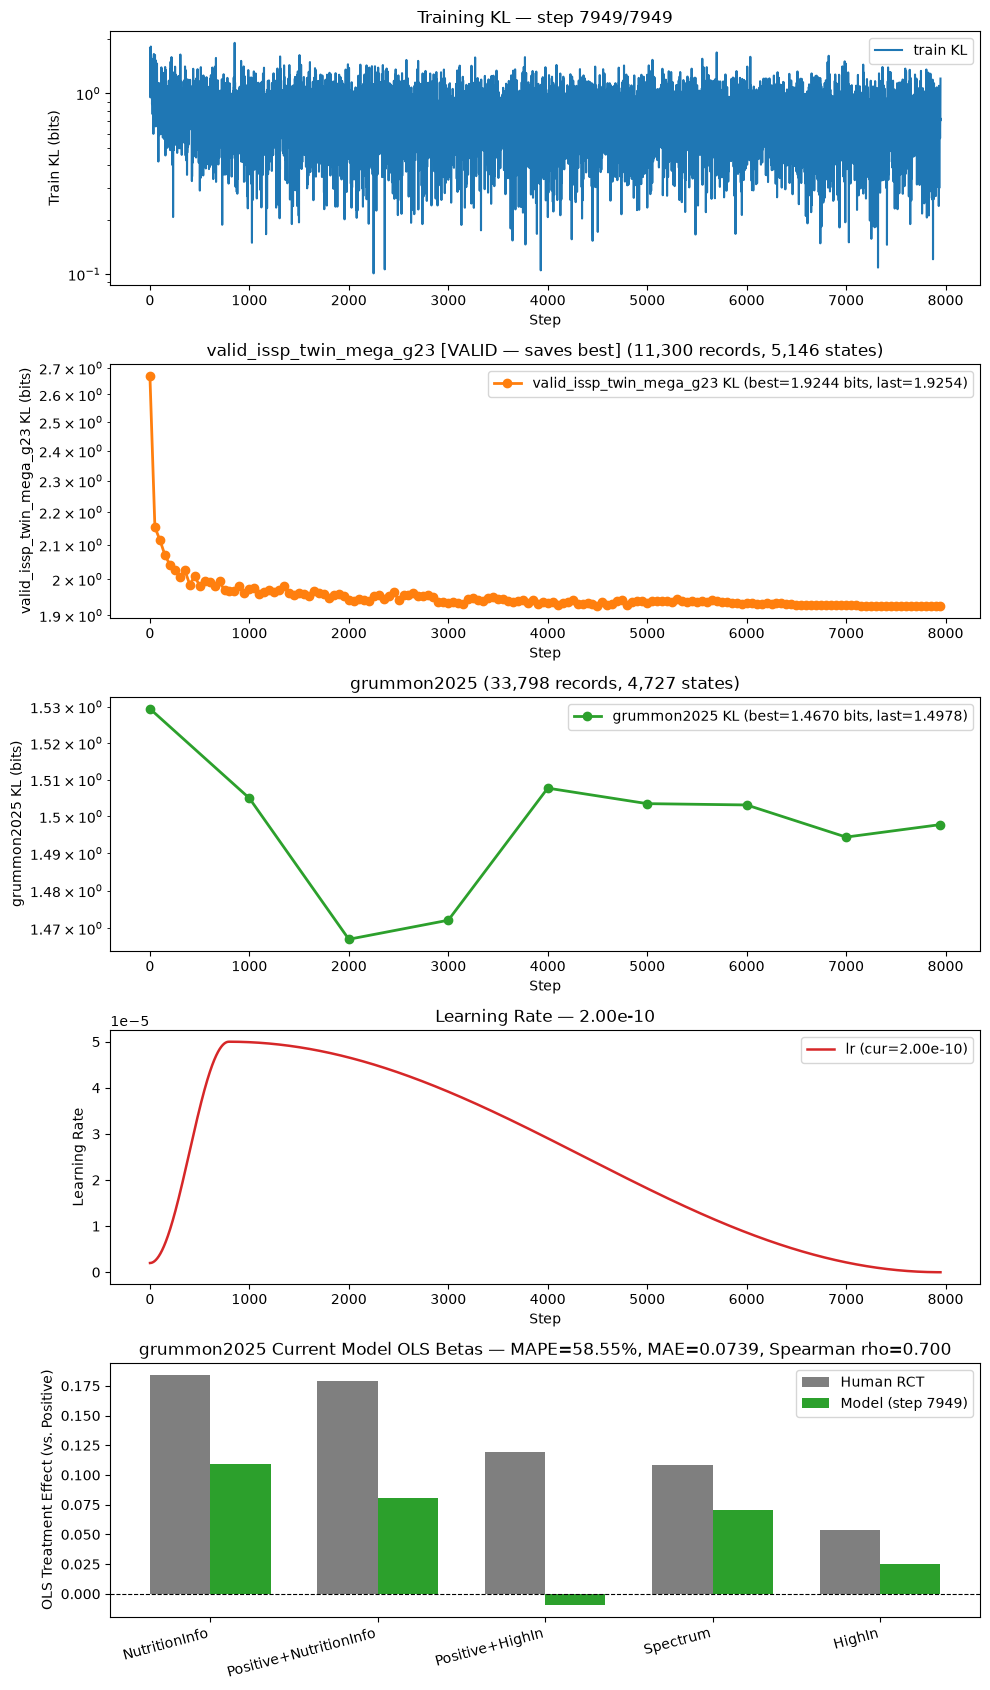

,epoch,step,train_kl,valid_issp_twin_mega_g23_kl,grummon2025_kl,grummon2025_OLS MAPE (%),grummon2025_OLS MAE,grummon2025_OLS MSE,grummon2025_Spearman rho
0,0,0,—,2.6697,1.5294,63.87,0.0650,0.0054,0.5000
1,1,50,1.2074,2.1531,—,—,—,—,—
2,1,100,0.7289,2.1146,—,—,—,—,—
3,1,150,1.0186,2.0706,—,—,—,—,—
4,1,200,0.8964,2.0418,—,—,—,—,—
5,1,250,0.6367,2.0274,—,—,—,—,—
6,1,300,0.6158,2.0068,—,—,—,—,—
7,1,350,0.5651,2.0271,—,—,—,—,—
8,1,400,1.0511,1.9848,—,—,—,—,—
9,1,450,0.9800,2.0082,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.1093,0.0751
Positive+NutritionInfo,0.1788,0.0807,0.0982
Positive+HighIn,0.1194,-0.0095,0.1290
Spectrum,0.1083,0.0702,0.0382
HighIn,0.0541,0.0249,0.0292


In [41]:
plotter = trainer.train()